# **Mission 3 - Exploratory Data Analysis (EDA) with the Sales Dataset using Pandas and d Matplotlib/Seaborn**

### **Objective:**

The goal of this assignment is to help you apply your knowledge of Python for basic operations, Pandas for data manipulation, and Matplotlib/Seaborn for visualizations. You'll be working with a real-world dataset, and your tasks will include loading the data, performing EDA, and visualising the results.

###  **Dataset**

The dataset represents transaction data from a retail business, specifically sales data for products sold in various stores. It contains multiple tables that provide insights into sales, invoices, and products. Let’s break down the tables and what they represent:

#### Sales Table:

InvoiceNo: The unique identifier for each invoice (or transaction).

StockCode: A unique identifier for each product.

Quantity: The number of units sold in each transaction.

UnitPrice: The price per unit of the product.

InvoiceDate: The date when the transaction occurred.

#### Invoice Table:

InvoiceNo: The same unique identifier for each invoice, linking the sales data with the invoice details.

Country: The country where the sale was made.

#### Product Table:

StockCode: A unique identifier for each product.

Description: The name or description of the product.

Product_Category: The category the product belongs to (e.g., "Gift", "Sign", "Mug").



You will need to merge them and perform the following tasks step by step.


### Task 1: Load the Excel File
#### Objective: Import the data from the provided Excel file into Python using Pandas.

Instructions:

1. Upload the provided excel file into Fabric environment
2. Read each sheet of the excel file as a separate dataframe. 
3. Name the dataframe for sales as df_sales, the dataframe for invoice as df_invoice and the dataframe for product as df_product
4. Display the first few rows of each DataFrame to understand its structure.



In [1]:
import pandas as pd

df_sales = pd.read_excel(
f"{notebookutils.nbResPath}/builtin/Online Sales Retailer 1.xlsx",
sheet_name='Sales'
)

df_invoice = pd.read_excel(
f"{notebookutils.nbResPath}/builtin/Online Sales Retailer 1.xlsx",
sheet_name='Invoice'
)

df_product = pd.read_excel(
f"{notebookutils.nbResPath}/builtin/Online Sales Retailer 1.xlsx",
sheet_name='Product'
)

display(df_sales.head())
display(df_invoice.head())
display(df_product.head())

StatementMeta(, 7698755b-de49-4489-a6eb-3738600cc92c, 3, Finished, Available, Finished, False)

SynapseWidget(Synapse.DataFrame, 9e3fa6a6-295b-4a8a-afc1-b97c212e2109)

SynapseWidget(Synapse.DataFrame, bcbc4aa8-a675-4a08-a54d-f7f93d3414c8)

SynapseWidget(Synapse.DataFrame, 7e2faf83-77bb-4d87-9528-040b6806c1b7)

### Task 2: Basic Python and Pandas Operations
#### Objective: Perform basic Python and Pandas operations to manipulate the data.

<mark>Instructions:</mark>

1. Create the Sales Column (Quantity * Unit Price) 

2. Check for missing values in the Sales DataFrame.

3. Replace any NaN values in the Sales and UnitPrice columns with 0.

4. Calculate basic descriptive statistics for the Quantity and UnitPrice columns (mean, median, mode, standard deviation).

In [2]:
# Create Sales column
df_sales['Sales'] = df_sales['Quantity'] * df_sales['UnitPrice']

# Check for missing values
print("Missing Values:")
print(df_sales.isnull().sum())

# Replace NaN values in Sales and UnitPrice with 0
df_sales['Sales'] = df_sales['Sales'].fillna(0)
df_sales['UnitPrice'] = df_sales['UnitPrice'].fillna(0)

# Descriptive statistics for Quantity and UnitPrice
print("Quantity Statistics")
print("Mean:", df_sales['Quantity'].mean())
print("Median:", df_sales['Quantity'].median())
print("Mode:", df_sales['Quantity'].mode()[0])
print("Standard Deviation:", df_sales['Quantity'].std())

print("\nUnitPrice Statistics")
print("Mean:", df_sales['UnitPrice'].mean())
print("Median:", df_sales['UnitPrice'].median())
print("Mode:", df_sales['UnitPrice'].mode()[0])
print("Standard Deviation:", df_sales['UnitPrice'].std())

StatementMeta(, 7698755b-de49-4489-a6eb-3738600cc92c, 5, Finished, Available, Finished, False)

Missing Values:
InvoiceNo      0
StockCode      0
Quantity       0
UnitPrice      0
InvoiceDate    0
Sales          0
dtype: int64
Quantity Statistics
Mean: 13.610961009642518
Median: 6.0
Mode: 1
Standard Deviation: 261.57756533193884

UnitPrice Statistics
Mean: 3.0835027678710807
Median: 1.95
Mode: 1.25
Standard Deviation: 5.17765256537552


### Task 3: Merging DataFrames
#### Objective: Merge the Sales, Invoice, and Product tables based on common keys to perform a comprehensive analysis.

Instructions:

1. Merge the Sales DataFrame with the Invoice DataFrame on InvoiceNo.

2. Merge the result with the Product DataFrame on StockCode

In [3]:
# Merge Sales and Invoice on InvoiceNo
df_merged = pd.merge(
df_sales,
df_invoice,
on='InvoiceNo',
how='inner'
)

# Merge the result with Product on StockCode
df_merged = pd.merge(
df_merged,
df_product,
on='StockCode',
how='inner'
)

# Display first few rows
display(df_merged.head())

# Check dimensions
print("Rows and Columns:", df_merged.shape)

StatementMeta(, 7698755b-de49-4489-a6eb-3738600cc92c, 6, Finished, Available, Finished, False)

SynapseWidget(Synapse.DataFrame, 3e1d349b-c046-467e-8941-0ecddd67b25d)

Rows and Columns: (83277, 9)


## Task 4: Exploratory Data Analysis (EDA)
### Objective: Conduct EDA by analysing the data, identifying patterns, trends, and outliers.

Instructions:

Use describe() to calculate summary statistics for numeric columns.

Perform basic filtering, such as filtering out sales with Quantity equal to 0.

Check for outliers in the Sales column by using a scatter plot.

StatementMeta(, 7698755b-de49-4489-a6eb-3738600cc92c, 8, Finished, Available, Finished, False)

SynapseWidget(Synapse.DataFrame, 08216d8f-4ed2-494a-b406-4c690a787cca)

Number of records after filtering: 83277


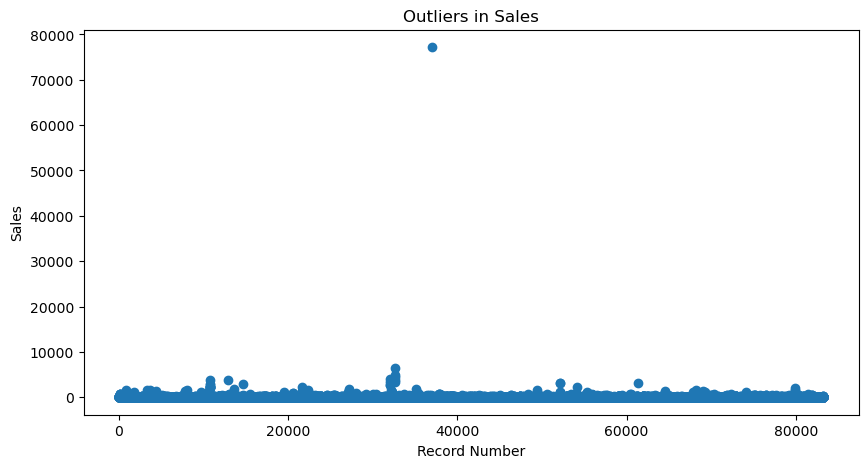

In [4]:
import matplotlib.pyplot as plt

# Summary statistics
display(df_merged.describe())

# Filter records where Quantity is not 0
df_filtered = df_merged[df_merged['Quantity'] != 0]

print("Number of records after filtering:", len(df_filtered))

# Scatter plot to identify outliers in Sales
plt.figure(figsize=(10, 5))
plt.scatter(df_filtered.index, df_filtered['Sales'])

plt.title('Outliers in Sales')
plt.xlabel('Record Number')
plt.ylabel('Sales')

plt.show()

#### Outlier Analysis

_Most sales are grouped around lower values, while a small number of transactions have much higher sales amounts. These high-value transactions stand out as outliers and may have a strong influence on the overall sales results._

In [5]:
# Data Validation and Structure Check
df_merged.info()
df_merged.head()

StatementMeta(, 7698755b-de49-4489-a6eb-3738600cc92c, 10, Finished, Available, Finished, False)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 83277 entries, 0 to 83276
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   InvoiceNo         83277 non-null  int64         
 1   StockCode         83277 non-null  int64         
 2   Quantity          83277 non-null  int64         
 3   UnitPrice         83277 non-null  float64       
 4   InvoiceDate       83277 non-null  datetime64[ns]
 5   Sales             83277 non-null  float64       
 6   Country           83277 non-null  object        
 7   Description       83277 non-null  object        
 8   Product_Category  83277 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(3), object(3)
memory usage: 5.7+ MB


,InvoiceNo,StockCode,Quantity,UnitPrice,InvoiceDate,Sales,Country,Description,Product_Category
0,536365,71053,6,3.39,2015-01-01,20.34,United Kingdom,PHOTO FRAME CORNICE,FRAME
1,536365,22752,2,7.65,2015-01-01,15.30,United Kingdom,TEA TIME TEAPOT IN GIFT BOX,GIFT
2,536365,84406,8,2.75,2015-01-01,22.00,United Kingdom,ZINC HEARTS PLANT POT HOLDER,HOLDER
3,536366,84029,6,3.39,2015-01-01,20.34,United Kingdom,FRENCH BLUE METAL DOOR SIGN 3,SIGN
4,536366,21730,6,4.25,2015-01-01,25.50,United Kingdom,CERAMIC CAKE DESIGN SPOTTED MUG,MUG


## Task 5: Data Visualisation – Scatter Plot, Histogram, and Line Chart
### Objective: Create scatter plots, histograms, and line charts to better understand the data.

Instructions:

Use a scatter plot to examine the relationship between Quantity and Sales.

Use a histogram to visualise the distribution of the Sales column.

Use a line chart to show the trend of Sales over time.

Write 1–2 sentences explaining the insights from each visualisation.

StatementMeta(, 7698755b-de49-4489-a6eb-3738600cc92c, 12, Finished, Available, Finished, False)

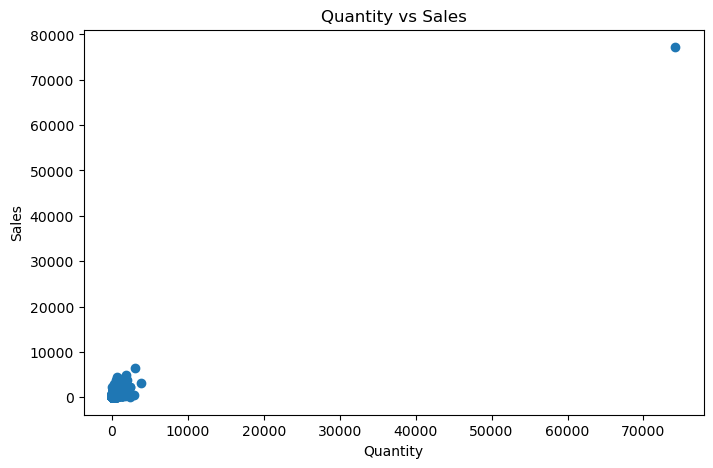

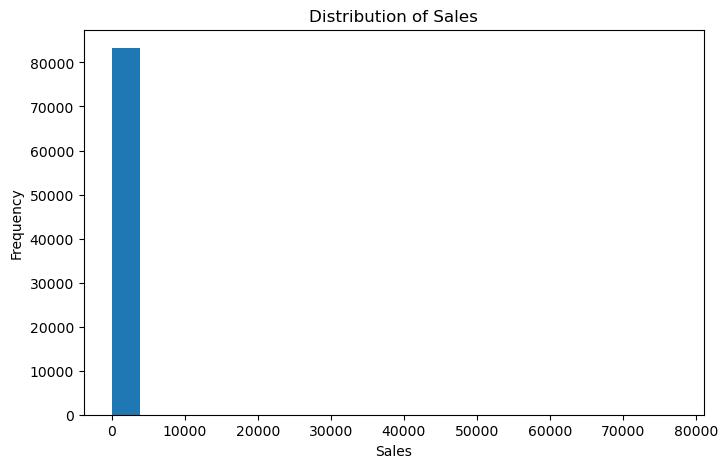

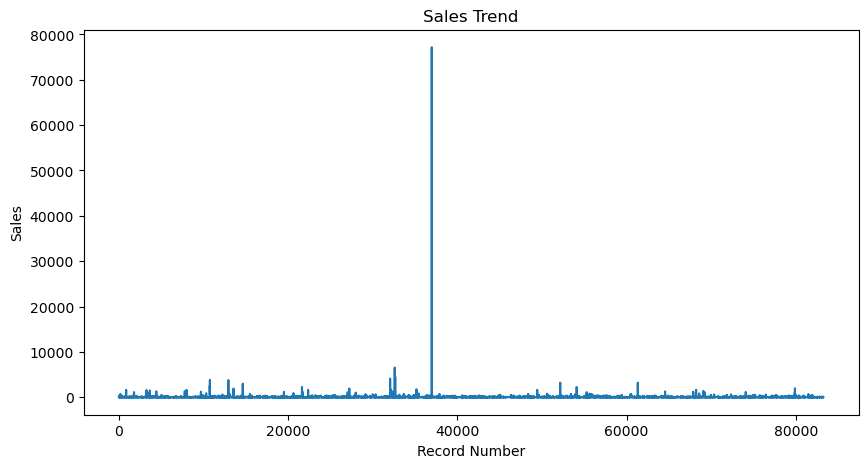

In [6]:
import matplotlib.pyplot as plt

# Scatter Plot: Quantity vs Sales
plt.figure(figsize=(8,5))
plt.scatter(df_merged['Quantity'], df_merged['Sales'])
plt.title('Quantity vs Sales')
plt.xlabel('Quantity')
plt.ylabel('Sales')
plt.show()

# Histogram: Distribution of Sales
plt.figure(figsize=(8,5))
plt.hist(df_merged['Sales'], bins=20)
plt.title('Distribution of Sales')
plt.xlabel('Sales')
plt.ylabel('Frequency')
plt.show()

# Line Chart: Sales Trend
plt.figure(figsize=(10,5))
plt.plot(df_merged['Sales'])
plt.title('Sales Trend')
plt.xlabel('Record Number')
plt.ylabel('Sales')
plt.show()

#### Quantity vs Sales
_The scatter plot shows a positive relationship between Quantity and Sales, meaning that larger quantities generally result in higher sales values. Most transactions are clustered at lower quantities and sales amounts, while one extreme outlier represents a very large order with unusually high sales._


#### Distribution of Sales
_The histogram shows that most sales transactions have relatively low sales values, with only a small number of high-value transactions. This indicates a right-skewed distribution, where a few large sales contribute significantly to overall revenue._


#### Sales Trend
_The line chart shows that sales fluctuate considerably across records rather than following a consistent pattern. Most sales values remain relatively low, with occasional spikes and one particularly large outlier that stands out from the rest of the dataset._

## Task 6: Correlation and Data Insights
### Objective: Identify the relationship between different numerical columns in the dataset.

Instructions:

Calculate the correlation between Quantity and Sales.

Visualise the correlation matrix using a heatmap.

Write 1–2 sentences explaining the insights from the visualisation.

StatementMeta(, 7698755b-de49-4489-a6eb-3738600cc92c, 14, Finished, Available, Finished, False)

Correlation between Quantity and Sales: 0.9786092498011646


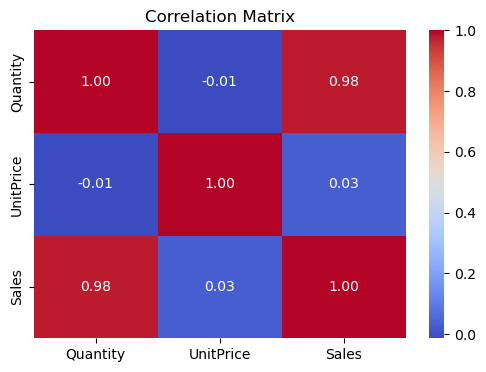

In [7]:
import seaborn as sns
import matplotlib.pyplot as plt

# Calculate correlation between Quantity and Sales
correlation = df_merged['Quantity'].corr(df_merged['Sales'])

print("Correlation between Quantity and Sales:", correlation)

# Correlation matrix
correlation_matrix = df_merged[['Quantity', 'UnitPrice', 'Sales']].corr()

# Heatmap
plt.figure(figsize=(6,4))
sns.heatmap(correlation_matrix,
annot=True,
cmap='coolwarm',
fmt='.2f')

plt.title('Correlation Matrix')
plt.show()

#### Insights

_The heatmap shows a very strong positive correlation between Quantity and Sales (0.98). This tells us that when more products are sold, the total sales value generally increases._

_UnitPrice appears to have a much weaker relationship with Sales, suggesting that the number of items sold has a bigger impact on overall sales than the price of individual products._

## Task 7: Grouping and Aggregating
### Objective: Perform grouping and aggregation operations to summarise the data.

Instructions:

GroupBy operation: Group by Product_Category and calculate the total Sales per category.

Create a Pivot Table to show Sales by Country and Product_Category.

In [8]:
# Total sales by Product Category
sales_by_category = (
    df_merged.groupby('Product_Category')['Sales']
    .sum()
    .reset_index()
)

print("Total Sales by Product Category:")
display(sales_by_category)

# Pivot Table: Sales by Country and Product Category
pivot_table = pd.pivot_table(
df_merged,
values='Sales',
index='Country',
columns='Product_Category',
aggfunc='sum',
fill_value=0
).reset_index()

print("Sales by Country and Product Category:")
display(pivot_table)

StatementMeta(, 7698755b-de49-4489-a6eb-3738600cc92c, 16, Finished, Available, Finished, False)

Total Sales by Product Category:


SynapseWidget(Synapse.DataFrame, 55e0bf1f-2174-4a0e-b978-6a29375f982c)

Sales by Country and Product Category:


SynapseWidget(Synapse.DataFrame, 79519084-ced3-4db0-8e0e-0e382b047615)

#### Grouping and Aggregation Findings

_The grouped results show that some product categories generate significantly more sales than others. The pivot table makes it easier to compare sales across different countries and product categories and identify which products perform best in each market._

## Submission Guidelines:
Submit the Python notebook with all the tasks and visualisations.

Ensure that each task is clearly explained and that all steps are followed.

Include markdown explanations where necessary to explain your thought process.